<a href="https://colab.research.google.com/github/hpedrazamartinez/ENCH680-CO2-Adsorption-ML/blob/main/ENCH680_CO2_Adsorption_Reproduction_Henry_and_Kyra.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ENCH 680 Course Project: Reproducing Yuan et al. (2021)
**Applied Machine Learning for Prediction of CO₂ Adsorption on Biomass Waste-Derived Porous Carbons**
*Environ. Sci. Technol.* 2021, 55, 11925–11936. https://doi.org/10.1021/acs.est.1c01849

Group members: Kyra Kjargaard, Henry Pedraza Martinez. University of Calgary, ENCH 680.

**What this notebook does**
1. Loads the authors' dataset (527 data points), [authors' GitHub repository](https://github.com/ssuvarnamanu/CO2-adsorption-by-biowaste-based-porous-carbon).
2. Repeats the preprocessing: random-forest imputation of TPV and MPV from SA, then drops S (%).
3. Trains the Chapter 3 baselines (a single decision tree with and without pre-pruning, and a random forest).
4. Approximate reproduction with modern libraries, not identical methodology of the the paper's three boosted-tree models (GBDT, XGBoost, LightGBM) with an 85/15 split, 5-fold CV and grid search.
5. Compares our results with Table 1 of the paper.
6. Interprets the model with permutation importance (MDA).


## 0. Install packages
Required packages: `pip install scikit-learn xgboost lightgbm pandas matplotlib openpyxl numpy`

In [ ]:
%pip install -q xgboost lightgbm openpyxl

In [ ]:
import json, os
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import (train_test_split, GridSearchCV, cross_val_score, KFold)
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.inspection import permutation_importance
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
import sklearn, xgboost, lightgbm
SEED = 42
os.makedirs("figs", exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "font.size": 11, "axes.spines.top": False, "axes.spines.right": False})
print("scikit-learn", sklearn.__version__, "| xgboost", xgboost.__version__, "| lightgbm", lightgbm.__version__)
RESULTS = {}

scikit-learn 1.6.1 | xgboost 3.4.1 | lightgbm 4.6.0


## 1. Data Loading

In [ ]:
import urllib.request
url = f"https://raw.githubusercontent.com/hpedrazamartinez/ENCH680-CO2-Adsorption-ML/main/data.xlsx"
urllib.request.urlretrieve(url, "data.xlsx")
print("Downloaded data.xlsx from", url)

Downloaded data.xlsx from https://raw.githubusercontent.com/hpedrazamartinez/ENCH680-CO2-Adsorption-ML/main/data.xlsx


In [ ]:
raw = pd.read_excel("data.xlsx")
print(raw.shape)
raw.describe().T.round(2)

(527, 11)


,count,mean,std,min,25%,50%,75%,max
Surface Area (m2/g),527.0,1488.15,728.61,2.48,955.50,1420.00,1960.00,3337.00
Total Pore Volume(cm3/g),499.0,0.80,0.45,0.02,0.48,0.69,1.03,3.09
Micropore Volume (cm3/g),317.0,0.52,0.27,0.04,0.31,0.48,0.69,1.29
C (%),527.0,76.32,12.59,40.40,69.83,79.10,85.33,96.96
H (%),527.0,1.68,1.59,0.00,0.00,1.50,2.41,6.01
N (%),527.0,3.26,3.71,0.00,0.72,2.16,4.45,38.15
O (%),527.0,18.17,11.63,0.00,9.92,15.43,22.91,54.00
S (%),527.0,0.13,0.93,0.00,0.00,0.00,0.00,13.20
Temp (°C),527.0,18.46,11.01,0.00,0.00,25.00,25.00,30.00
Pressure (bar),527.0,0.87,0.31,0.10,1.00,1.00,1.00,1.01


## 2. Preprocessing (same as the paper's Supporting Information, Tables S3 and S4)
TPV and MPV are strongly correlated with surface area (SA), so the authors imputed the missing values with a random forest that uses SA as the only input (80/20 split). After that, S (%) is dropped, which leaves 9 input features.

In [ ]:
SA = "Surface Area (m2/g)"; TPV = "Total Pore Volume(cm3/g)"; MPV = "Micropore Volume (cm3/g)"
TARGET = "CO2 uptake (mmol/g)"
df = raw.copy()
imp_rows = []
for col in [TPV, MPV]:
    known = df[[SA, col]].dropna()
    Xk, yk = known[[SA]].values, known[col].values
    Xtr, Xte, ytr, yte = train_test_split(Xk, yk, test_size=0.2, random_state=SEED)
    for name, m in [("Linear regression", LinearRegression()), ("Random forest", RandomForestRegressor(random_state=SEED))]:
        m.fit(Xtr, ytr)
        imp_rows.append([col, name, r2_score(ytr, m.predict(Xtr)), r2_score(yte, m.predict(Xte))])
    rf_imp = RandomForestRegressor(random_state=SEED).fit(Xtr, ytr)
    miss = df[col].isna()
    df.loc[miss, col] = rf_imp.predict(df.loc[miss, [SA]].values)
    print(f"{col}: imputed {miss.sum()} values")
imp = pd.DataFrame(imp_rows, columns=["feature", "model", "train R2", "test R2"]).round(3)
RESULTS["imputation"] = imp.to_dict(orient="records")
df = df.drop(columns=["S (%)"])
FEATURES = [c for c in df.columns if c != TARGET]
print("Features used:", FEATURES)
imp

Total Pore Volume(cm3/g): imputed 28 values
Micropore Volume (cm3/g): imputed 210 values
Features used: ['Surface Area (m2/g)', 'Total Pore Volume(cm3/g)', 'Micropore Volume (cm3/g)', 'C (%)', 'H (%)', 'N (%)', 'O (%)', 'Temp (°C)', 'Pressure (bar)']


,feature,model,train R2,test R2
0,Total Pore Volume(cm3/g),Linear regression,0.832,0.801
1,Total Pore Volume(cm3/g),Random forest,0.977,0.926
2,Micropore Volume (cm3/g),Linear regression,0.588,0.710
3,Micropore Volume (cm3/g),Random forest,0.964,0.687


## 3. Train/test split (85/15, random_state=42, same as the authors' code)

In [ ]:
df[FEATURES] = df[FEATURES].astype(float)
X, y = df[FEATURES], df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.15, random_state=SEED)
print("Train:", X_train.shape, "Test:", X_test.shape)
cv5 = KFold(n_splits=5, shuffle=True, random_state=SEED)

def evaluate(name, model, Xtr=None, ytr=None, Xte=None, yte=None, store=True):
    Xtr = X_train if Xtr is None else Xtr; ytr = y_train if ytr is None else ytr
    Xte = X_test if Xte is None else Xte; yte = y_test if yte is None else yte
    model.fit(Xtr, ytr)
    p_tr, p_te = model.predict(Xtr), model.predict(Xte)
    cv = cross_val_score(model, Xtr, ytr, cv=cv5, scoring="r2")
    row = {"model": name,
           "train R2": r2_score(ytr, p_tr),
           "5-fold CV R2": cv.mean(), "CV R2 std": cv.std(),
           "test R2": r2_score(yte, p_te),
           "test RMSE": np.sqrt(mean_squared_error(yte, p_te)),
           "test MAE": mean_absolute_error(yte, p_te)}
    return row, model, p_tr, p_te

Train: (447, 9) Test: (80, 9)


## 4. Chapter 3 baselines: decision tree and random forest
Chapter 3 shows that a single tree with no limits keeps splitting until each leaf is pure, which leads to overfitting. Pre-pruning (max_depth, min_samples_split, min_samples_leaf) controls this. A random forest averages many bootstrapped, decorrelated trees to reduce variance.

In [ ]:
rows, models, preds = [], {}, {}

r, m, ptr, pte = evaluate("Decision tree (unpruned)", DecisionTreeRegressor(random_state=SEED))
rows.append(r); models[r["model"]] = m; preds[r["model"]] = (ptr, pte)
print("Unpruned tree depth:", m.get_depth(), "| leaves:", m.get_n_leaves())

dt_grid = GridSearchCV(DecisionTreeRegressor(random_state=SEED),
                       {"max_depth": [3, 4, 5, 6, 8, 10, None],
                        "min_samples_split": [2, 5, 10, 20],
                        "min_samples_leaf": [1, 2, 4, 8]}, cv=cv5, scoring="r2", n_jobs=-1).fit(X_train, y_train)
print("Pre-pruned tree best params:", dt_grid.best_params_)
r, m, ptr, pte = evaluate("Decision tree (pre-pruned)", DecisionTreeRegressor(random_state=SEED, **dt_grid.best_params_))
rows.append(r); models[r["model"]] = m; preds[r["model"]] = (ptr, pte)

rf_grid = GridSearchCV(RandomForestRegressor(random_state=SEED, n_jobs=-1),
                       {"n_estimators": [200, 500], "max_depth": [None, 10, 6],
                        "max_features": [1.0, 0.6, 0.33], "min_samples_leaf": [1, 2]},
                       cv=cv5, scoring="r2", n_jobs=-1).fit(X_train, y_train)
print("Random forest best params:", rf_grid.best_params_)
r, m, ptr, pte = evaluate("Random forest (tuned)", RandomForestRegressor(random_state=SEED, n_jobs=-1, **rf_grid.best_params_))
rows.append(r); models[r["model"]] = m; preds[r["model"]] = (ptr, pte)
RESULTS["dt_params"] = dt_grid.best_params_; RESULTS["rf_params"] = rf_grid.best_params_
pd.DataFrame(rows).round(3)

Unpruned tree depth: 23 | leaves: 440
Pre-pruned tree best params: {'max_depth': 6, 'min_samples_leaf': 1, 'min_samples_split': 2}
Random forest best params: {'max_depth': None, 'max_features': 0.33, 'min_samples_leaf': 1, 'n_estimators': 200}


,model,train R2,5-fold CV R2,CV R2 std,test R2,test RMSE,test MAE
0,Decision tree (unpruned),1.00,0.593,0.061,0.612,1.014,0.692
1,Decision tree (pre-pruned),0.85,0.706,0.054,0.749,0.816,0.564
2,Random forest (tuned),0.97,0.774,0.061,0.767,0.787,0.578


## 5. Reproducing the paper: GBDT, XGBoost, LightGBM
5a. With the authors' final hyperparameters (taken from their published notebook).

5b. With our own grid search (5-fold CV on the training set), as the paper describes.

In [ ]:
paper_models = {
    "GBDT": GradientBoostingRegressor(learning_rate=0.05, max_depth=4, min_samples_leaf=1, min_samples_split=2,
                                      n_estimators=300, subsample=0.5, random_state=SEED),
    "XGB": XGBRegressor(colsample_bytree=1, learning_rate=0.05, max_depth=4, n_estimators=100,
                        subsample=0.5, random_state=SEED, eval_metric="rmse"),
    "LGB": LGBMRegressor(boosting_type="dart", colsample_bytree=1, learning_rate=0.2, max_depth=4,
                         n_estimators=300, num_leaves=5, reg_lambda=0.8, subsample=1, random_state=SEED, verbose=-1),
}
for k, m in paper_models.items():
    r, m, ptr, pte = evaluate(f"{k} (authors' hyperparameters)", m)
    rows.append(r); models[r["model"]] = m; preds[r["model"]] = (ptr, pte)
pd.DataFrame(rows).round(3).tail(3)

,model,train R2,5-fold CV R2,CV R2 std,test R2,test RMSE,test MAE
3,GBDT (authors' hyperparameters),0.982,0.821,0.051,0.836,0.659,0.498
4,XGB (authors' hyperparameters),0.908,0.793,0.062,0.787,0.752,0.545
5,LGB (authors' hyperparameters),0.898,0.775,0.071,0.762,0.795,0.586


In [ ]:
grids = {
    "GBDT": (GradientBoostingRegressor(random_state=SEED),
             {"n_estimators": [100, 300, 500], "learning_rate": [0.02, 0.05, 0.1],
              "max_depth": [3, 4, 5], "subsample": [0.5, 0.8, 1.0]}),
    "XGB": (XGBRegressor(random_state=SEED, eval_metric="rmse", n_jobs=1),
            {"n_estimators": [100, 300, 500], "learning_rate": [0.02, 0.05, 0.1],
             "max_depth": [3, 4, 5], "subsample": [0.5, 0.8, 1.0]}),
    "LGB": (LGBMRegressor(random_state=SEED, verbose=-1, n_jobs=1),
            {"n_estimators": [100, 300, 500], "learning_rate": [0.02, 0.05, 0.1],
             "num_leaves": [5, 15, 31], "min_child_samples": [5, 10, 20]}),
}
tuned_params = {}
for k, (est, g) in grids.items():
    gs = GridSearchCV(est, g, cv=cv5, scoring="r2", n_jobs=-1).fit(X_train, y_train)
    tuned_params[k] = gs.best_params_
    print(k, "best params:", gs.best_params_)
    r, m, ptr, pte = evaluate(f"{k} (our grid search)", est.set_params(**gs.best_params_))
    rows.append(r); models[r["model"]] = m; preds[r["model"]] = (ptr, pte)
RESULTS["tuned_params"] = tuned_params
results = pd.DataFrame(rows).set_index("model")
RESULTS["main_table"] = results.round(4).reset_index().to_dict(orient="records")
results.round(3)

GBDT best params: {'learning_rate': 0.05, 'max_depth': 4, 'n_estimators': 500, 'subsample': 0.5}
XGB best params: {'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 500, 'subsample': 0.5}
LGB best params: {'learning_rate': 0.1, 'min_child_samples': 5, 'n_estimators': 300, 'num_leaves': 5}


,train R2,5-fold CV R2,CV R2 std,test R2,test RMSE,test MAE
model,,,,,,
Decision tree (unpruned),1.000,0.593,0.061,0.612,1.014,0.692
Decision tree (pre-pruned),0.850,0.706,0.054,0.749,0.816,0.564
Random forest (tuned),0.970,0.774,0.061,0.767,0.787,0.578
GBDT (authors' hyperparameters),0.982,0.821,0.051,0.836,0.659,0.498
XGB (authors' hyperparameters),0.908,0.793,0.062,0.787,0.752,0.545
LGB (authors' hyperparameters),0.898,0.775,0.071,0.762,0.795,0.586
GBDT (our grid search),0.992,0.823,0.051,0.847,0.638,0.469
XGB (our grid search),0.999,0.834,0.049,0.841,0.649,0.509
LGB (our grid search),0.964,0.810,0.058,0.805,0.719,0.548


##6. Comparison with Table 1 of the paper

In [ ]:
paper = pd.DataFrame({"train R2": [0.98, 0.96, 0.92], "5-fold CV R2": [0.81, 0.81, 0.78],
                      "test R2": [0.84, 0.83, 0.78], "test RMSE": [0.66, 0.68, 0.77]},
                     index=["GBDT", "XGB", "LGB"])
comp = []
for k in ["GBDT", "XGB", "LGB"]:
    for src, lab in [(paper.loc[k], "Paper (Table 1)"),
                     (results.loc[f"{k} (authors' hyperparameters)"], "Ours, authors' hyperparameters"),
                     (results.loc[f"{k} (our grid search)"], "Ours, own grid search")]:
        comp.append({"model": k, "source": lab, **{c: src[c] for c in paper.columns}})
comp = pd.DataFrame(comp)
RESULTS["comparison"] = comp.round(3).to_dict(orient="records")
comp.round(2)

,model,source,train R2,5-fold CV R2,test R2,test RMSE
0,GBDT,Paper (Table 1),0.98,0.81,0.84,0.66
1,GBDT,"Ours, authors' hyperparameters",0.98,0.82,0.84,0.66
2,GBDT,"Ours, own grid search",0.99,0.82,0.85,0.64
3,XGB,Paper (Table 1),0.96,0.81,0.83,0.68
4,XGB,"Ours, authors' hyperparameters",0.91,0.79,0.79,0.75
5,XGB,"Ours, own grid search",1.00,0.83,0.84,0.65
6,LGB,Paper (Table 1),0.92,0.78,0.78,0.77
7,LGB,"Ours, authors' hyperparameters",0.90,0.77,0.76,0.80
8,LGB,"Ours, own grid search",0.96,0.81,0.81,0.72


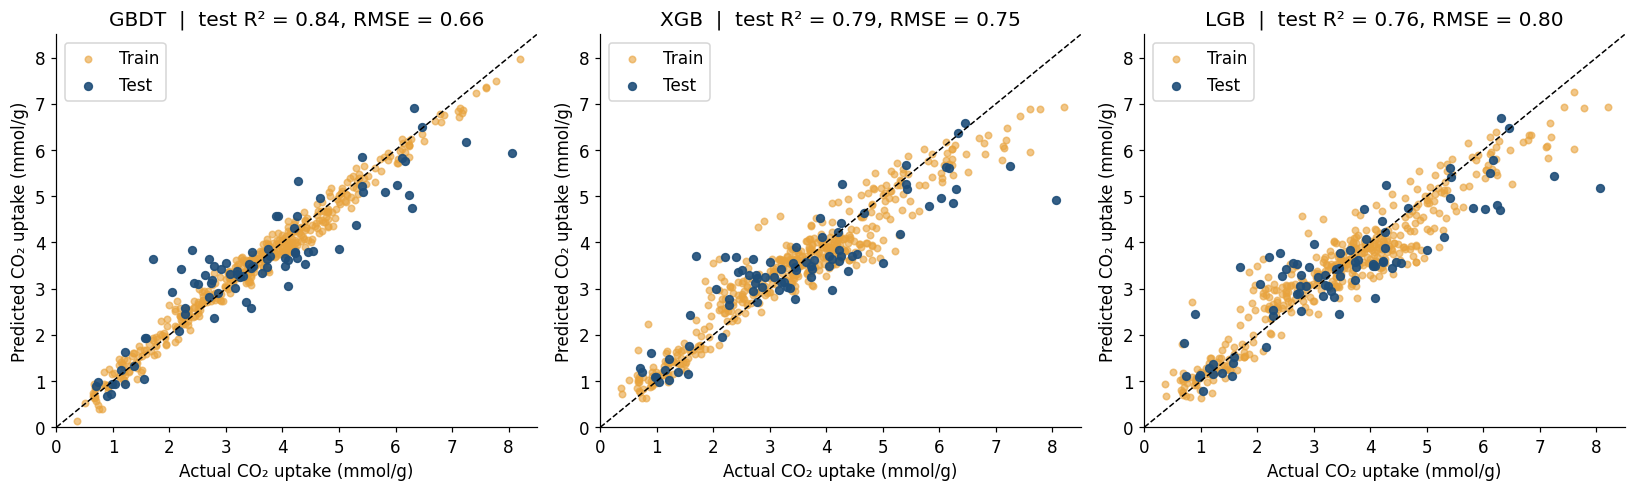

In [ ]:
best = "GBDT (authors' hyperparameters)"
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
for ax, name in zip(axes, ["GBDT (authors' hyperparameters)", "XGB (authors' hyperparameters)", "LGB (authors' hyperparameters)"]):
    ptr, pte = preds[name]
    ax.scatter(y_train, ptr, s=18, c="#E8A33D", alpha=0.6, label="Train")
    ax.scatter(y_test, pte, s=26, c="#1F4E79", alpha=0.9, label="Test")
    ax.plot([0, 8.5], [0, 8.5], "k--", lw=1)
    ax.set_xlim(0, 8.5); ax.set_ylim(0, 8.5)
    rr = results.loc[name]
    ax.set_title(f"{name.split(' ')[0]}  |  test R² = {rr['test R2']:.2f}, RMSE = {rr['test RMSE']:.2f}")
    ax.set_xlabel("Actual CO₂ uptake (mmol/g)"); ax.set_ylabel("Predicted CO₂ uptake (mmol/g)")
    ax.legend(loc="upper left")
plt.tight_layout(); plt.savefig("figs/fig2_parity.png", dpi=200); plt.show()

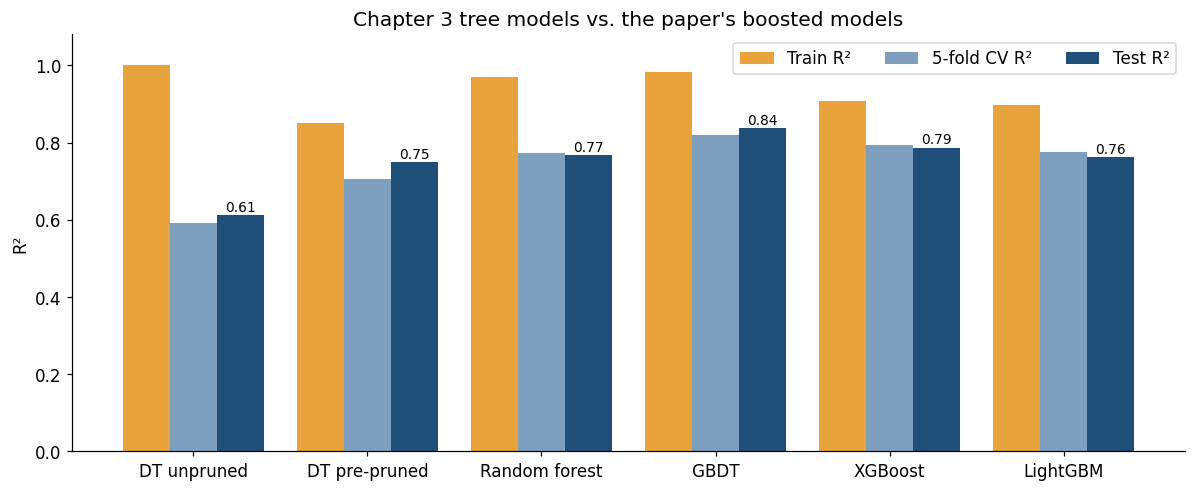

In [ ]:
plot_models = ["Decision tree (unpruned)", "Decision tree (pre-pruned)", "Random forest (tuned)",
               "GBDT (authors' hyperparameters)", "XGB (authors' hyperparameters)", "LGB (authors' hyperparameters)"]
labels = ["DT unpruned", "DT pre-pruned", "Random forest", "GBDT", "XGBoost", "LightGBM"]
sub = results.loc[plot_models]
xx = np.arange(len(sub)); w = 0.27
fig, ax = plt.subplots(figsize=(11, 4.6))
ax.bar(xx - w, sub["train R2"], w, label="Train R²", color="#E8A33D")
ax.bar(xx, sub["5-fold CV R2"], w, label="5-fold CV R²", color="#7F9FBF")
ax.bar(xx + w, sub["test R2"], w, label="Test R²", color="#1F4E79")
for i, v in enumerate(sub["test R2"]): ax.text(i + w, v + 0.01, f"{v:.2f}", ha="center", fontsize=9)
ax.set_xticks(xx); ax.set_xticklabels(labels); ax.set_ylim(0, 1.08); ax.set_ylabel("R²")
ax.set_title("Chapter 3 tree models vs. the paper's boosted models"); ax.legend(ncol=3, loc="upper right")
plt.tight_layout(); plt.savefig("figs/fig3_model_comparison.png", dpi=200); plt.show()

##7. Model interpretation: permutation importance (MDA) and partial dependence
The paper uses permutation importance (mean decrease in accuracy). Chapter 3 warns that impurity-based importance can be misleading when features are correlated (SA, TPV, MPV), so permutation importance on the test set is the safer choice.

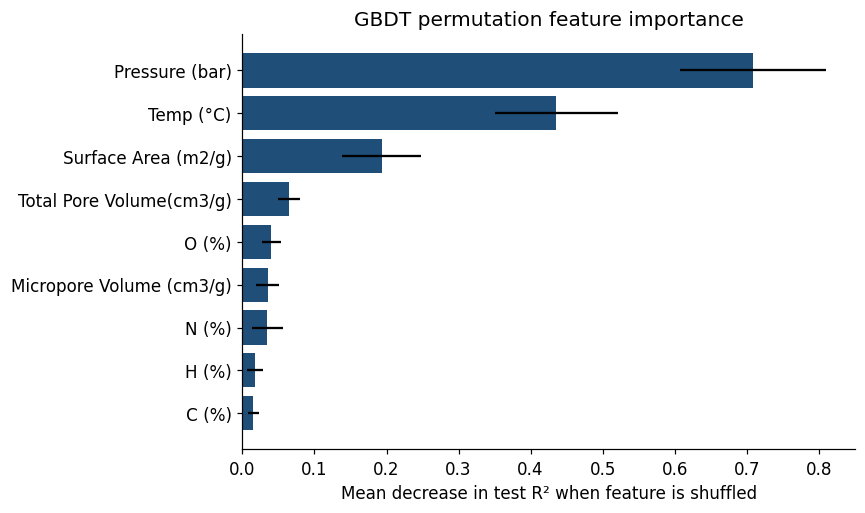

,feature,MDA (drop in R²),std,impurity importance
8,Pressure (bar),0.709,0.101,0.310
7,Temp (°C),0.436,0.086,0.188
0,Surface Area (m2/g),0.193,0.055,0.101
1,Total Pore Volume(cm3/g),0.065,0.016,0.092
6,O (%),0.040,0.013,0.060
2,Micropore Volume (cm3/g),0.035,0.016,0.093
5,N (%),0.034,0.021,0.068
4,H (%),0.017,0.011,0.042
3,C (%),0.015,0.007,0.046


In [ ]:
gbdt = models[best]
pi = permutation_importance(gbdt, X_test, y_test, n_repeats=30, random_state=SEED, scoring="r2")
imp_df = pd.DataFrame({"feature": FEATURES, "MDA (drop in R²)": pi.importances_mean, "std": pi.importances_std,
                       "impurity importance": gbdt.feature_importances_}).sort_values("MDA (drop in R²)", ascending=True)
RESULTS["importance"] = imp_df.round(4).to_dict(orient="records")
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.barh(imp_df["feature"], imp_df["MDA (drop in R²)"], xerr=imp_df["std"], color="#1F4E79")
ax.set_xlabel("Mean decrease in test R² when feature is shuffled"); ax.set_title("GBDT permutation feature importance")
plt.tight_layout(); plt.savefig("figs/fig4_permutation_importance.png", dpi=200); plt.show()
imp_df.sort_values("MDA (drop in R²)", ascending=False).round(3)

##10. Save results

In [ ]:
RESULTS["versions"] = {"scikit-learn": sklearn.__version__, "xgboost": xgboost.__version__, "lightgbm": lightgbm.__version__}
with open("results.json", "w") as f: json.dump(RESULTS, f, indent=2, default=float)
results.round(3).to_csv("results_main_table.csv")
print("Saved results.json, results_main_table.csv, and figures in ./figs")

Saved results.json, results_main_table.csv, and figures in ./figs
